In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit
plt.style.use('seaborn-v0_8-whitegrid')

import xgboost as xgb

这里的特征工程策略基于 Boosting 思想  
逐层增加模型复杂度，用模型表现的变化来推断数据中存在哪种特征关系

用 Stumps（深度=1 的决策树）作为基线模型
- 每棵树只能根据单个特征进行一次划分，所以模型只能学习单变量与目标变量的关系
- 可以通过观察特征重要性来发现最关键的单个特征，然后尝试单个特征的转换，如 `e^x, log(x), x^2, x^3, tanh(x)`

用 2-level 树（深度=2）来检测特征交互
- 深度=2 意味着模型可以根据一个特征再在某个子区域用另一个特征做划分
- 这样模型可以捕捉两个特征之间的交互效应
- 比较 validation error 是否比深度=1 时显著下降；如果显著下降，说明特征交互很重要
- 可以计算 SHAP 值和 sumnmary plot 来发现究竟是哪些特征有这种交互效应

In [2]:
clean_df = pd.read_csv('../EDA/clean_train.csv')
clean_df.head()

,date_id,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,V2,V3,V4,V5,V6,V7,V8,forward_returns,risk_free_rate,target
0,1006,0,0,0,1,0,-1,0,0,0,...,0.986772,0.970899,0.986111,0.0,0.000661,0.0,0.000661,-0.000669,0.000121,-0.001100
1,1007,0,0,0,1,0,-1,0,0,0,...,0.984788,0.972884,0.984788,0.0,0.000661,0.0,0.000661,0.005348,0.000121,0.004917
2,1008,0,0,0,1,0,-1,0,0,0,...,0.982143,0.834656,0.983466,0.0,0.000661,0.0,0.000661,0.001996,0.000121,0.001565
3,1009,0,0,0,1,0,-1,0,0,0,...,0.980159,0.928571,0.979497,0.0,0.000661,0.0,0.000661,-0.001327,0.000121,-0.001758
4,1010,0,0,0,1,0,0,0,1,0,...,1.000000,0.997354,1.000000,0.0,0.000661,0.0,0.000661,-0.003987,0.000119,-0.004415


### 构建初始特征集

所有的 M*, E*, I*, P*, V*, S*, D* 特征  
过去一天的 risk_free_rate  
过去一天的 forward_returns  
过去一天的 market_excess_returns (target)

In [3]:
M_cols = [c for c in clean_df.columns if c.startswith('M')]
E_cols = [c for c in clean_df.columns if c.startswith('E')]
I_cols = [c for c in clean_df.columns if c.startswith('I')]
P_cols = [c for c in clean_df.columns if c.startswith('P')]
V_cols = [c for c in clean_df.columns if c.startswith('V')]
S_cols = [c for c in clean_df.columns if c.startswith('S')]
D_cols = [c for c in clean_df.columns if c.startswith('D')]

groups = {
    "Market Dynamics (M*)": M_cols,
    "Macro Economic (E*)": E_cols,
    "Interest Rate (I*)": I_cols,
    "Price/Valuation (P*)": P_cols,
    "Volatility (V*)": V_cols,
    "Sentiment (S*)": S_cols,
    "Dummy/Binary (D*)": D_cols
}


clean_df['lagged_risk_free_rate'] = clean_df['risk_free_rate'].shift(1)
clean_df['lagged_forward_returns'] = clean_df['forward_returns'].shift(1)
clean_df['lagged_target'] = clean_df['target'].shift(1)

base_features   = M_cols + E_cols + I_cols + P_cols + V_cols + S_cols + D_cols
lagged_features = ['lagged_risk_free_rate', 'lagged_forward_returns', 'lagged_target']

features = base_features + lagged_features

clean_df = clean_df.dropna(subset=['lagged_forward_returns', 'lagged_target'])
print(f"Number of features to investigate: {len(features)}")

Number of features to investigate: 88


In [4]:
if clean_df.isna().any().any() == False:
    print('No NaNs')
else:
    print('There is still NaNs')

No NaNs


### Day Forward-Chaining Nested Cross-Validation
队友提到了这种模型驱动的特征工程方法有数据窥探的风险，于是想了用 nested CV 尽可能的避免这个问题
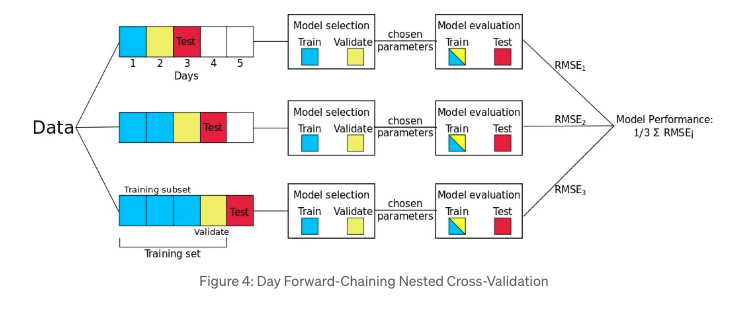

In [ ]:
X = clean_df[features]
y = clean_df['target']

In [14]:
dates = clean_df['date_id'].unique()
start_date_id = int(dates[0])
print('Start date_id:', start_date_id)
end_date_id = int(dates[-1])
print('End date_id:', end_date_id)
n_dates = end_date - start_date + 1
print('Total number of trading days in the training dataset:', n_dates)

Start date_id: 1007
End date_id: 8989
Total number of trading days in the training dataset: 7983


In [35]:
PURGE = 5
TRAIN_SIZE = 252 * 3
TEST_SIZE = 126

OUTER_FOLDS = ((n_dates - TRAIN_SIZE - PURGE - TEST_SIZE) // TEST_SIZE) + 1
print('Number of outer folds:', OUTER_FOLDS)

for i in range(OUTER_FOLDS):
    outer_train_start = start_date_id + outer_i * TEST_SIZE
    outer_train_end   = outer_train_start + TRAIN_SIZE - 1
    outer_test_start  = outer_train_end + PURGE + 1

    # For all folds except the last, use full TEST_SIZE
    # For the final fold, extend to end_date_id
    if i == OUTER_FOLDS - 1:
        outer_test_end = end_date_id
    else:
        outer_test_end = outer_test_start + TEST_SIZE - 1

    print('\nFold {}:'.format(i+1))
    print('  Train: {}–{},'.format(outer_train_start, outer_train_end),
          'length: {}'.format(outer_train_end - outer_train_start + 1))
    print('  Test:  {}–{},'.format(outer_test_start, outer_test_end),
          'length: {}'.format(outer_test_end - outer_test_start + 1))

Number of outer folds: 57

Fold 1:
  Train: 1007–1762, length: 756
  Test:  1768–1893, length: 126

Fold 2:
  Train: 1007–1888, length: 882
  Test:  1894–2019, length: 126

Fold 3:
  Train: 1007–2014, length: 1008
  Test:  2020–2145, length: 126

Fold 4:
  Train: 1007–2140, length: 1134
  Test:  2146–2271, length: 126

Fold 5:
  Train: 1007–2266, length: 1260
  Test:  2272–2397, length: 126

Fold 6:
  Train: 1007–2392, length: 1386
  Test:  2398–2523, length: 126

Fold 7:
  Train: 1007–2518, length: 1512
  Test:  2524–2649, length: 126

Fold 8:
  Train: 1007–2644, length: 1638
  Test:  2650–2775, length: 126

Fold 9:
  Train: 1007–2770, length: 1764
  Test:  2776–2901, length: 126

Fold 10:
  Train: 1007–2896, length: 1890
  Test:  2902–3027, length: 126

Fold 11:
  Train: 1007–3022, length: 2016
  Test:  3028–3153, length: 126

Fold 12:
  Train: 1007–3148, length: 2142
  Test:  3154–3279, length: 126

Fold 13:
  Train: 1007–3274, length: 2268
  Test:  3280–3405, length: 126

Fold 14:


再把每一个 inner loop 的 train 分成 4 个 Folds

In [46]:
PURGE = 5
TRAIN_SIZE = 252 * 3
TEST_SIZE = 126
INNER_FOLDS = 4

# OUTER LOOP
OUTER_FOLDS = ((n_dates - TRAIN_SIZE - PURGE - TEST_SIZE) // TEST_SIZE) + 1
print("Number of outer folds:", OUTER_FOLDS)

for outer_i in range(OUTER_FOLDS):
    outer_train_start = start_date_id
    outer_train_end = start_date_id + TRAIN_SIZE + outer_i * TEST_SIZE - 1
    outer_test_start = outer_train_end + PURGE + 1
    # For the last fold, extend test set to end of dataset
    if outer_i == OUTER_FOLDS - 1:
        outer_test_end = end_date_id
    else:
        outer_test_end = outer_test_start + TEST_SIZE - 1

    print(
        f"\nOuter Fold {outer_i+1}: "
        f"Train {outer_train_start}–{outer_train_end} "
        f"(len={outer_train_end - outer_train_start + 1}) | "
        f"Test {outer_test_start}–{outer_test_end} "
        f"(len={outer_test_end - outer_test_start + 1})"
    )

    # INNER SPLITS
    train_len = outer_train_end - outer_train_start + 1
    step = train_len // (INNER_FOLDS + 1)  # size of each inner block

    for inner_i in range(INNER_FOLDS):
        inner_train_end = outer_train_start + (inner_i + 1) * step - 1
        inner_val_start = inner_train_end + PURGE + 1
        inner_val_end   = min(inner_val_start + step - 1, outer_train_end)

        print(f"  Inner Fold {inner_i+1}: "
              f"Train {outer_train_start}–{inner_train_end}  "
              f"| Val {inner_val_start}–{inner_val_end}")

Number of outer folds: 57

Outer Fold 1: Train 1007–1762 (len=756) | Test 1768–1893 (len=126)
  Inner Fold 1: Train 1007–1157  | Val 1163–1313
  Inner Fold 2: Train 1007–1308  | Val 1314–1464
  Inner Fold 3: Train 1007–1459  | Val 1465–1615
  Inner Fold 4: Train 1007–1610  | Val 1616–1762

Outer Fold 2: Train 1007–1888 (len=882) | Test 1894–2019 (len=126)
  Inner Fold 1: Train 1007–1182  | Val 1188–1363
  Inner Fold 2: Train 1007–1358  | Val 1364–1539
  Inner Fold 3: Train 1007–1534  | Val 1540–1715
  Inner Fold 4: Train 1007–1710  | Val 1716–1888

Outer Fold 3: Train 1007–2014 (len=1008) | Test 2020–2145 (len=126)
  Inner Fold 1: Train 1007–1207  | Val 1213–1413
  Inner Fold 2: Train 1007–1408  | Val 1414–1614
  Inner Fold 3: Train 1007–1609  | Val 1615–1815
  Inner Fold 4: Train 1007–1810  | Val 1816–2014

Outer Fold 4: Train 1007–2140 (len=1134) | Test 2146–2271 (len=126)
  Inner Fold 1: Train 1007–1232  | Val 1238–1463
  Inner Fold 2: Train 1007–1458  | Val 1464–1689
  Inner Fold 3

In [ ]:
def rolling_window_split(data, train_size=10, test_size=3):
    """Create rolling window splits for time series cross-validation."""
    n_samples = len(data)
    splits = []
    
    for i in range(n_samples - train_size - test_size + 1):
        train_start = i
        train_end = i + train_size
        test_start = train_end
        test_end = test_start + test_size
        
        train_idx = list(range(train_start, train_end))
        test_idx = list(range(test_start, test_end))
        
        splits.append((train_idx, test_idx))
    
    return splits